# LIVE CODE 5
  NAMA: Putri Joeliya
  
Batch : CODA-RMT-020

### Import Library

In [9]:
#import Library
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

data = pd.read_csv('multiTimeline.csv')
data.head()


,Week,Pulau Pari: (Indonesia)
0,2022-03-27,16
1,2022-04-03,13
2,2022-04-10,18
3,2022-04-17,29
4,2022-04-24,35


## Data Loading

In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Week                     126 non-null    object
 1   Pulau Pari: (Indonesia)  126 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.1+ KB


In [11]:
data.rename(columns={'Week' : 'Date', 'Pulau Pari: (Indonesia)' : 'Popularitas'}, inplace=True)


In [12]:
data

,Date,Popularitas
0,2022-03-27,16
1,2022-04-03,13
2,2022-04-10,18
3,2022-04-17,29
4,2022-04-24,35
...,...,...
121,2024-07-21,43
122,2024-07-28,34
123,2024-08-04,32
124,2024-08-11,36


In [13]:
data['Date'] = data['Date'].astype('datetime64[ns]')

In [14]:
data = data.set_index('Date')

<Axes: xlabel='Date'>

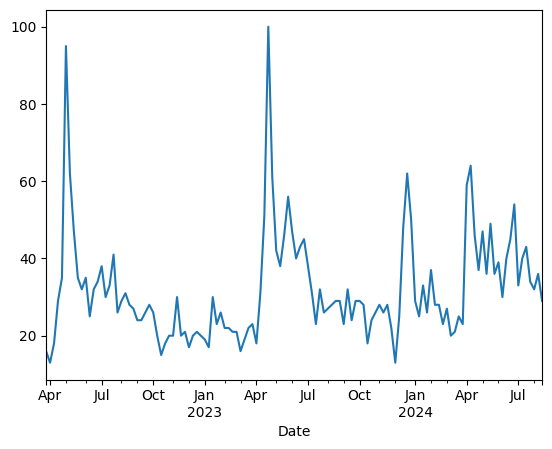

In [15]:
data['Popularitas'].plot()

## Exploratory Data Analysis (EDA)

### Time Series Decomposition

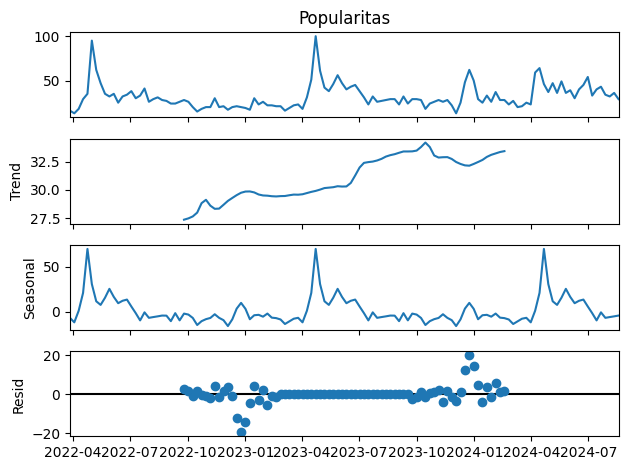

In [16]:
res = seasonal_decompose(data['Popularitas'], model='additive')
ax=res.plot()
plt.show()

data menunjukan adanya pola naik turun dengan beberpa lonjakan yang sangat tajam pada periode tertentu, hal ini bisa terjadi karna adanya masa masa tertentu seperti tahun baru dan hari raya
1. trend: menunjukan adanya pertumbuhan naik yang bertahap dari tahun 2022 dan seterusnya sampai nilai lonjakan lebih dari 32.5 di pertengahan 2024. walaupunada sedikit penurunan setelahnya namun masih terlihat ada lonjakan naik.
2. seasonal: menjukan pola yang berulang walaupu di beberapa bagian terdapat lonjakan yang sangat tinggi. hal ini wajar karena tempat wisata biasanya memiliki waktu waktu tertentu yang padat seperti hari libur dll
3. residual: titik tidak seslalu berkumpul di area 0 tetapi juga ada yang arahnya miring dan juga terlihat banyak outlier.

karena variasinya tidak tetap maka model additive tidak cocok dengan dataset ini

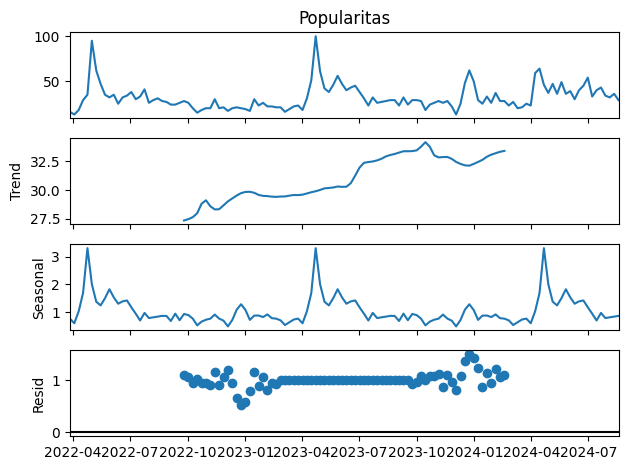

In [17]:
res = seasonal_decompose(data['Popularitas'], model='multiplicative')
ax=res.plot()
plt.show()

terlihat pada residual yang ada dalam dataset titiknya mendekati 1 yang dimana hal ini menandakan model dapat di gunakan denga baik

### Ekstasi Periode Seasonal

In [18]:
seasonal_max = res.seasonal[res.seasonal==res.seasonal.max()].reset_index()
seasonal_min = res.seasonal[res.seasonal==res.seasonal.min()].reset_index()
seasonal_max.head()

,Date,seasonal
0,2022-04-24,3.303952
1,2023-04-23,3.303952
2,2024-04-21,3.303952


menunjukan seasonalitynya kurang lebih berjarak 1 tahun di bulan yang sama dan hari yang hanya berbeda selisih 1 - 2 hari setiap tahunnya.

In [19]:
seasonal_max['Date'].dt.month.head()

,Date
0,4
1,4
2,4


berdasarkan hasil di atas bahwa puncak popularitas pencarian kata kunci berulang pada bulan 4 atau april

In [20]:
seasonal_min['Date'].dt.month.head()

,Date
0,12
1,12


sebaliknya titik terendah pencarian ada di bulan 12 yaitu desember

### Uji Stationary

In [21]:
from statsmodels.tsa.stattools import adfuller

def check_stationarity(series):

    result = adfuller(series.values)

    print('ADF Statistic: %f' % result[0])
    print('p-value: %f' % result[1])
    print('Critical Values:')
    for key, value in result[4].items():
        print('\t%s: %.3f' % (key, value))

    if (result[1] <= 0.05) & (result[4]['5%'] > result[0]):
        print("\u001b[32mStationary\u001b[0m")
    else:
        print("\x1b[31mNon-stationary\x1b[0m")

In [22]:
check_stationarity(data['Popularitas'])

ADF Statistic: -3.893116
p-value: 0.002086
Critical Values:
	1%: -3.485
	5%: -2.886
	10%: -2.580
Stationary


setelah melakukan stationary check pada dataset. hasil yang di dapatkan adalah dataset bersifat stationary.

hal ini terlihat dari nilai p-value yang lebih kecil daro 0.05 yang berarti H0 di tolak

dan ADF yang angkanya lebih kecil dari semua Critical values yang ada.

sehingga nilai parameter d untuk ARIMA adalah 0

## Model Definition and Training

### ARIMA

first try : karna data sudah stationer maka q= 0. dan parameter lainnya diisi dengan p=1, d= 0

In [23]:
model = ARIMA(data['Popularitas'], order=(1, 0, 0))
result = model.fit()
print('AIC:',result.aic)

AIC: 961.2750910822137


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


nilainya 961.27, nilai ini belum bisa di pastikan apakah nilai ini baik atau buruk sehingga perlu di komparasikan dengan ARIMA yang nilainya berbeda dan mencari nilai AIC yang paling kecil

## Model Evaluation

In [24]:
print('MSE:',mean_squared_error(data['Popularitas'], result.predict()))
print('MAE:',mean_absolute_error(data['Popularitas'], result.predict()))

MSE: 115.17870083052162
MAE: 6.863503209791699


MAE yang di hasilkan sebesar 6.86 atau 6% - 7% dimana angka tersebut adalah jumlah yang meleset dari nilai asli. jadi masih di batas wajar dari range 0-100



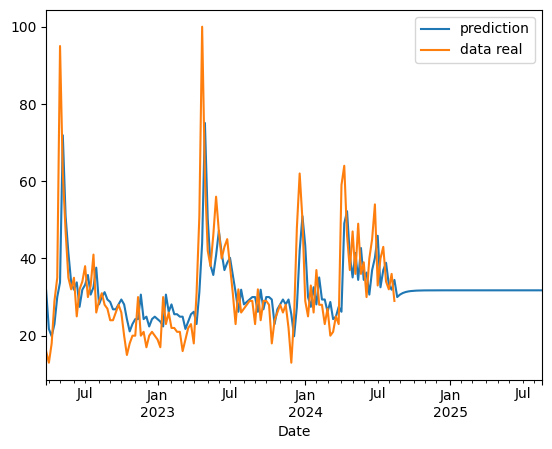

In [25]:
result.predict(0, len(data)+52).plot(label='prediction')
data['Popularitas'].plot(label='data real')
plt.legend()

karena ada gari mendarat di garis prediksi maka kita perlu melakukan tuning dan karna parameter yang dilakukan sebelumnya random maka kita harus melakukan ulang dan mencari nilai terbaik dengan Tuning

## Model Improvement

### Tuning

In [26]:
def find_best_model(data, num_p, num_d, num_q):
  df = pd.DataFrame()
  pdq = [[],[],[]]
  aic = []
  for p in range(num_p + 1):
    for d in range(num_d + 1):
      for q in range(num_q + 1):

        try:
          model = ARIMA(data, order=(p, d, q))
          result = model.fit()
          pdq[0].append(p)
          pdq[1].append(d)
          pdq[2].append(q)
          aic.append(result.aic)
        except:
          pass

  df['p'] = pdq[0]
  df['d'] = pdq[1]
  df['q'] = pdq[2]
  df['AIC'] = aic

  df.sort_values('AIC', inplace=True)

  return df.p.iloc[0], df.d.iloc[0], df.q.iloc[0], df.AIC.iloc[0], df

In [27]:
p,d,q,AIC,df = find_best_model(data['Popularitas'], 10, 0, 10)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  

In [30]:
df.head()

,p,d,q,AIC
11,1,0,0,961.275091
2,0,0,2,961.604941
22,2,0,0,962.162996
13,1,0,2,962.336499
12,1,0,1,962.366513


model yang pali baik dari hasil tuning adalah moden dengan AIC terendah yaitu p=1, d=0 dan q=0

In [31]:
model = ARIMA(data['Popularitas'], order=(1, 0, 0))
result = model.fit()
print('MSE:',mean_squared_error(data['Popularitas'], result.predict()))
print('MAE:',mean_absolute_error(data['Popularitas'], result.predict()))

MSE: 115.17870083052162
MAE: 6.863503209791699


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


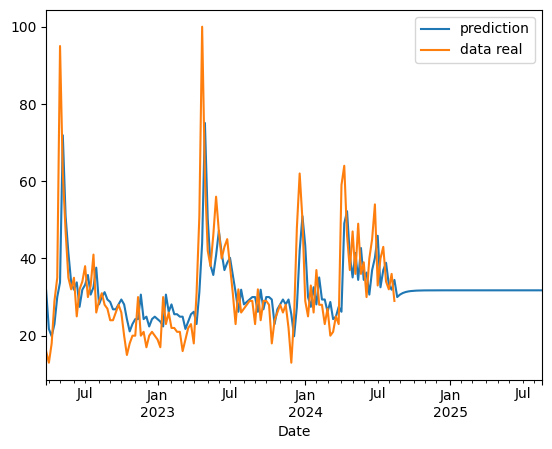

In [32]:
result.predict(0, len(data)+52).plot(label='prediction')
data['Popularitas'].plot(label='data real')
plt.legend()

hasilnya sama seperti sebelunya karna memang AIC yang paling rendah parameternya sudah di gunakan saat first try jadi memang ini adalah hasil yang paling terbaik

## Model Inference

In [33]:
result.predict(len(data), len(data)+7)

,predicted_mean
2024-08-25,30.002406
2024-09-01,30.638723
2024-09-08,31.042651
2024-09-15,31.299060
2024-09-22,31.461827
2024-09-29,31.565149
2024-10-06,31.630737
2024-10-13,31.672372


hasil di atas memuat hasil yaitu data kanan memunjukan bahwa tingkat popularitas di masa depan. dan perkiraan angka popularitas akan bergerak stabil dengan rentang 30 -31 pada periode tersebut